# Домашнє завдання: Візуалізація даних з Matplotlib

## Опис завдання
У цьому домашньому завданні ви продовжите працювати з датасетом про оренду велосипедів `yulu_rental.csv`, але тепер будете використовувати бібліотеку Matplotlib для створення більш складних та налаштованих візуалізацій.

**Опис колонок:**
- `datetime` - дата та час
- `season` - квартал (1-Q1, 2-Q2, 3-Q3, 4-Q4)
- `holiday` - чи є день святковим (0=ні, 1=так)
- `workingday` - чи є день робочим (0=ні, 1=так)
- `weather` - погодні умови (1=ясно, 2=туман, 3=легкий дощ, 4=сильний дощ)
- `temp` - температура в градусах Цельсія
- `atemp` - відчувається як температура
- `humidity` - вологість (%)
- `windspeed` - швидкість вітру
- `casual` - кількість випадкових користувачів
- `registered` - кількість зареєстрованих користувачів
- `count` - загальна кількість орендованих велосипедів

## Підготовка даних

---


🌱 Коментар щодо сезонності

Колонка season у датасеті представляє саме квартали року, а не метеорологічні сезони. Тому всі аналізи сезонності ви можете будувати на основі кварталів.

Водночас дані були зібрані в Індії, де поділ на сезони інший, ніж у Європі чи США. Якщо ви хочете дослідити сезонність відповідно до індійської системи сезонів, можна створити окрему колонку.

Справжні сезони в Індії:

| Сезон        | Місяці                     |
| ------------ | -------------------------- |
| Winter       | December–February (12,1,2) |
| Summer       | March–May (3,4,5)          |
| Monsoon      | June–September (6,7,8,9)   |
| Post-monsoon | October–November (10,11)   |


Тоді потрібно зробити нову колонку weather_season_india, мапнувши місяці так:

12, 1, 2 → 1 (Winter)

3, 4, 5 → 2 (Summer)

6–9 → 3 (Monsoon)

10–11 → 4 (Post-Monsoon)

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Завантаження даних
df = pd.read_csv('yulu_rental.csv')
# Перетворення datetime у правильний формат
df['datetime'] = pd.to_datetime(df['datetime'])
df.set_index('datetime', inplace=True)

# Додаткові колонки
df['date'] = df.index.date
df['day'] = df.index.day
df['week'] = df.index.isocalendar().week
df['weekday_num'] = df.index.weekday
df['weekday'] = df.index.day_name()
df['year'] = df.index.year
df['month'] = df.index.month
df['hour'] = df.index.hour

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
df.head()

,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count,date,day,week,weekday_num,weekday,year,month,hour
datetime,,,,,,,,,,,,,,,,,,,
2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0,3,13,16,2011-01-01,1,52,5,Saturday,2011,1,0
2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0,8,32,40,2011-01-01,1,52,5,Saturday,2011,1,1
2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0,5,27,32,2011-01-01,1,52,5,Saturday,2011,1,2
2011-01-01 03:00:00,1,0,0,1,9.84,14.395,75,0.0,3,10,13,2011-01-01,1,52,5,Saturday,2011,1,3
2011-01-01 04:00:00,1,0,0,1,9.84,14.395,75,0.0,0,1,1,2011-01-01,1,52,5,Saturday,2011,1,4


## Завдання 1: Порівняння Pandas vs Matplotlib

**Завдання:**
Побудуйте лінійний графік середньої кількості оренд помісячно впродовж всього періоду в даних двома способами:
1. Використовуючи Pandas (DataFrame.plot())
2. Використовуючи Matplotlib безпосередньо

В обох методах додайте маркери-кружечки. Можна також задати свій відмінний від стандартного колір.

Підказка: отримати потрібний формат даних найзручніше з методом датафрейму `resample`.

**Опишіть свої спостереження:** чим відрізняються 2 побудованих графіки? Який вам більше подобається?

In [6]:
monthly_rent = df['count'].resample('ME').mean()
monthly_rent

,count
datetime,
2011-01-31,54.645012
2011-02-28,73.641256
2011-03-31,86.849776
2011-04-30,111.026374
2011-05-31,174.809211
2011-06-30,196.877193
2011-07-31,203.614035
2011-08-31,182.666667
2011-09-30,174.622517


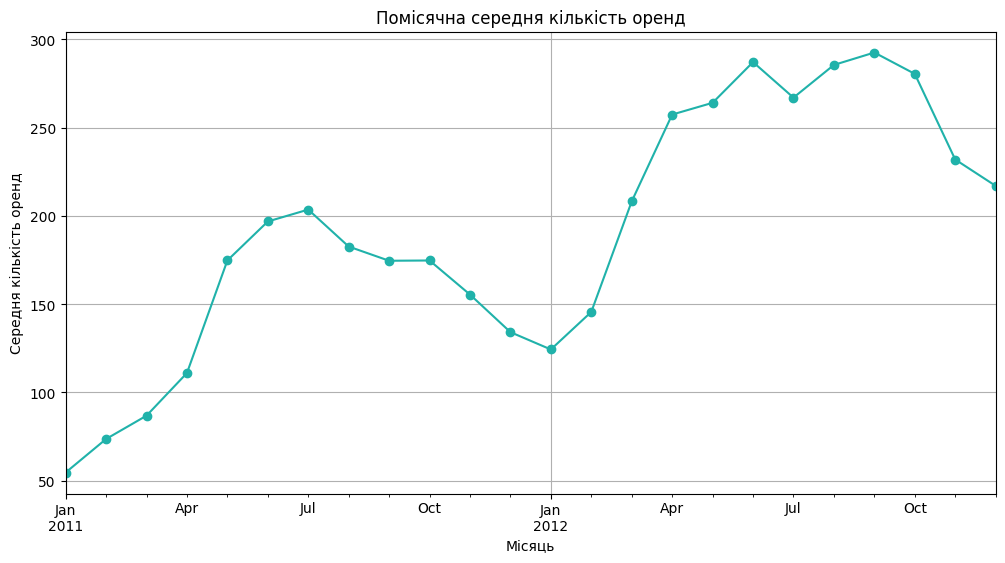

In [7]:
monthly_rent.plot(
    kind='line',
    color='#20B2AA',
    marker='o',
    figsize=(12, 6),
    title='Помісячна середня кількість оренд',
    xlabel='Місяць',
    ylabel='Середня кількість оренд',
    grid=True
);

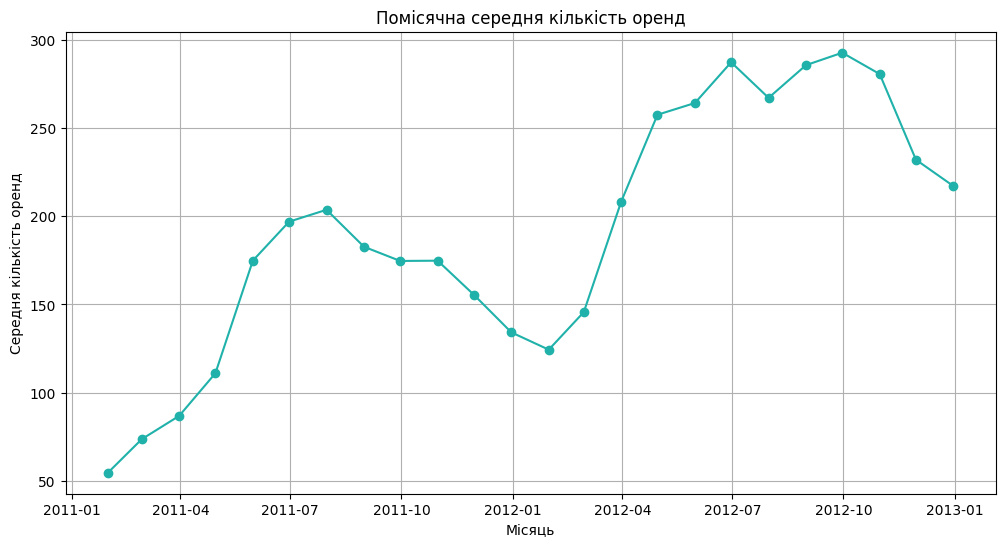

In [8]:
plt.figure(figsize=(12, 6))
plt.plot(monthly_rent, 'o-', color='#20B2AA')
plt.title('Помісячна середня кількість оренд')
plt.xlabel('Місяць')
plt.ylabel('Середня кількість оренд')
plt.grid(True);

Pandas подобається тим, що робить усе швидко й без зайвого коду — сам підписує осі й ставить дати як треба. Але якщо треба докрутити якусь графічну дрібницю вручну, тут уже рятує Matplotlib

## Завдання 2: Робота зі списками та numpy

**Завдання:**
Вам задані 3 списки:
1. Номер дня тижня.
2. Продажі в тиждень 1.
3. Продажі в тиждень 2.

Створіть графік, на якому лінійними графіками різних кольорів накладено продажі за обидва тижні.

Обовʼязково додайте назву графіку, підписи вісям ОХ, ОУ, назви кожного з рядів даних, легенду.

**Дайте відповіді на питання**
1. Судячи з графіку, в який тиждень проодажі були стабільніше?
2. Чи можете ви підкріпити свій висновок обчисленнями? Якими саме? Можна (але не обовʼязково) навести ці обчислення.

In [9]:
# Дані у вигляді списків
days = [1, 2, 3, 4, 5, 6, 7] # 1 - це понеділок
sales_week1 = [1349,1562,1600,1606,1510,959,822]  # Продажі за тиждень1
sales_week2 = [1321,1263,1162,1406,1421,1248,1204]  # Продажі за тиждень1

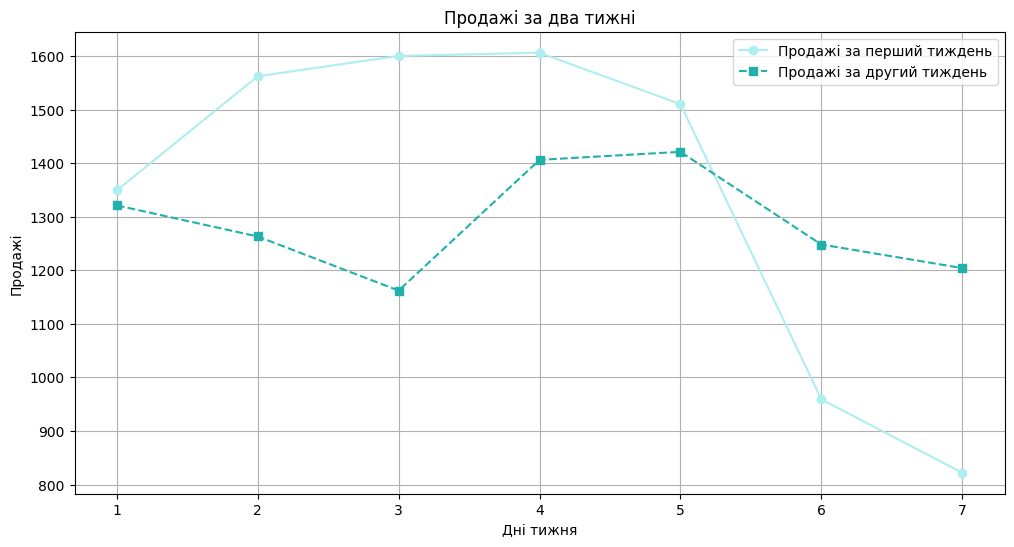

In [10]:
plt.figure(figsize=(12, 6))
plt.plot(days, sales_week1, ls='-', marker='o', color='#AFEEEE', label='Продажі за перший тиждень')
plt.plot(days, sales_week2, ls='--', marker='s', color='#20B2AA', label='Продажі за другий тиждень')

plt.title('Продажі за два тижні')
plt.xlabel('Дні тижня')
plt.ylabel('Продажі')
plt.grid(True)
plt.legend()

plt.show()

**Порівняльна стабільність:** На другому тижні динаміка продажів демонструє відносну сталість та передбачуваність. На противагу цьому, перший тиждень відзначається вираженою мінливістю показників.

**Аналіз коливань:** Протягом першого тижня спостерігалося підвищення продажів у робочі дні з подальшим різким падінням у вихідні (майже на 50%). Саме ця суттєва різниця між буднями та вікендом і сформувала загальну нестабільність на початку спостережуваного періоду.

In [11]:
s1 = np.array(sales_week1)
s2 = np.array(sales_week2)

print(f"Розмах тижня 1: {s1.max() - s1.min()}")
print(f"Розмах тижня 2: {s2.max() - s2.min()}")

std1 = np.std(sales_week1)
std2 = np.std(sales_week2)

print(f"Стандартне відхилення тиждень 1: {std1:.2f}")
print(f"Стандартне відхилення тиждень 2: {std2:.2f}")

Розмах тижня 1: 784
Розмах тижня 2: 259
Стандартне відхилення тиждень 1: 300.00
Стандартне відхилення тиждень 2: 90.91


## Завдання 3: Subplot - 2x2 сітка графіків

**Завдання:**
Створіть сітку 2x2 з чотирма різними графіками, використовуючи `plt.subplot()`:
1. Лінійний графік середньої температури помісячно.
2. Стовпчикова діаграма середньої годинної кількості оренд за кварталами.
3. Гістограма вологості за всіма погодинними вимірами.
4. Scatter plot температури vs кількості оренд.

Кожен підграфік має містити всі необхідні підписи. Дашборд має містити назву.

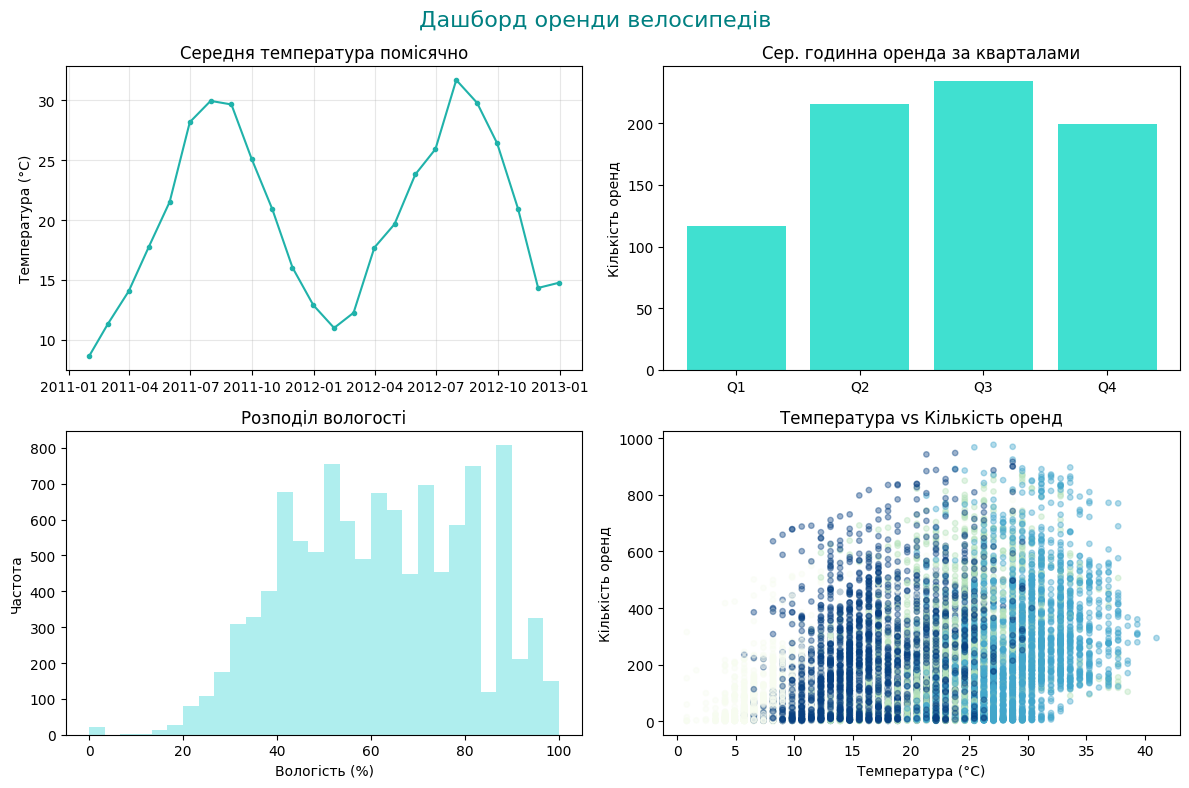

In [14]:
plt.figure(figsize=(12, 8))
plt.suptitle('Дашборд оренди велосипедів', fontsize=16, color='#008081')

# Лінійний графік
plt.subplot(2, 2, 1)
monthly_temp = df['temp'].resample('ME').mean()
plt.plot(monthly_temp, color='#20B2AA', marker='.')
plt.title('Середня температура помісячно')
plt.ylabel('Температура (°C)')
plt.grid(True, alpha=0.3)

# Стовпчиковий графік
plt.subplot(2, 2, 2)
seasonal_avg = df.groupby('season')['count'].mean()
quarters = ['Q1', 'Q2', 'Q3', 'Q4']
plt.bar(quarters, seasonal_avg, color='#40E0D0')
plt.title('Сер. годинна оренда за кварталами')
plt.ylabel('Кількість оренд')

# Гістограма
plt.subplot(2, 2, 3)
plt.hist(df['humidity'], bins=30, color='#AFEEEE')
plt.title('Розподіл вологості')
plt.xlabel('Вологість (%)')
plt.ylabel('Частота')

# Scatter plot
plt.subplot(2, 2, 4)
plt.scatter(df['temp'], df['count'], s=15, c=df['season'], cmap='GnBu', alpha=0.4)
plt.title('Температура vs Кількість оренд')
plt.xlabel('Температура (°C)')
plt.ylabel('Кількість оренд')

plt.tight_layout()
plt.show()

## Завдання 4: Subplots - об'єктно-орієнтований підхід

**Завдання:**
Створіть той самий набір графіків, але використовуючи `fig, ax = plt.subplots()`.

**Дайте відповідь на питання своїми словами**
- Чим відрізняється підхід побудови кількох графіків на одній фігурі з `plt.subplots()` від `plt.subplot()`?

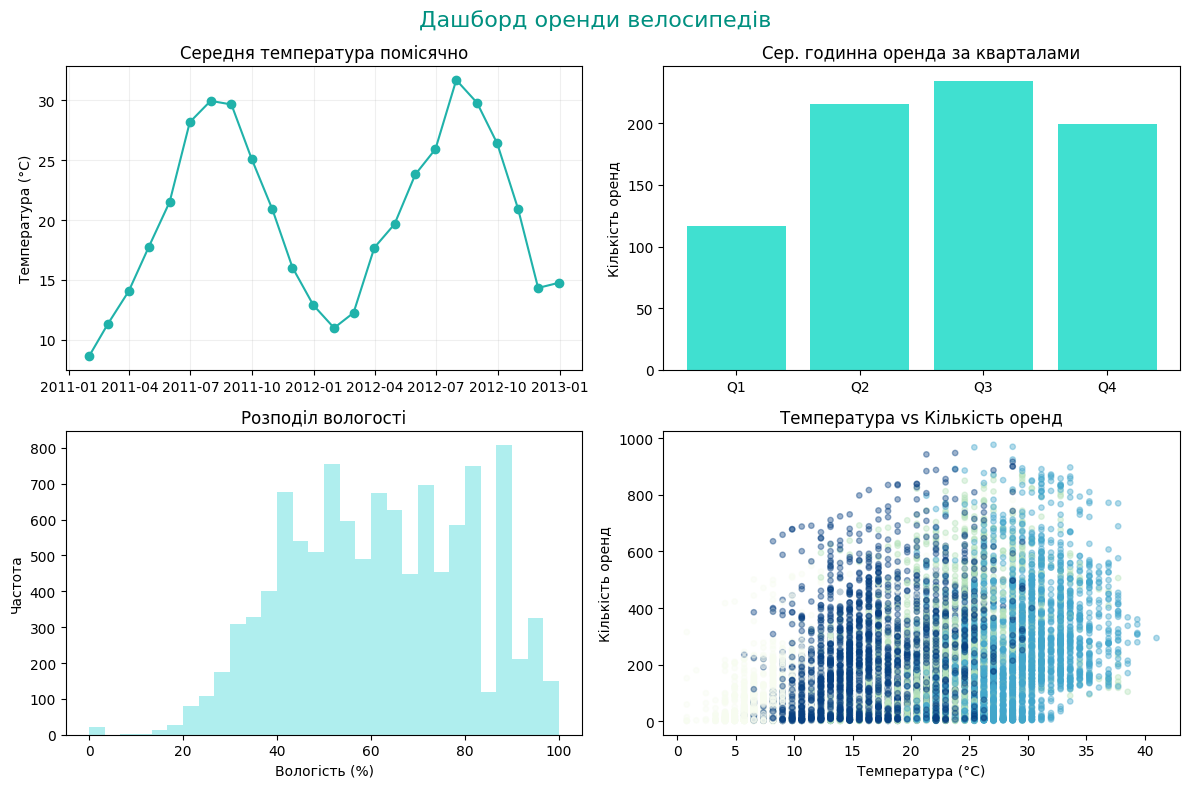

In [15]:
fig, ax = plt.subplots(2, 2, figsize=(12, 8))
fig.suptitle('Дашборд оренди велосипедів', fontsize=16, color='#009080')

# 1: Лінійний
monthly_temp = df['temp'].resample('ME').mean()
ax[0, 0].plot(monthly_temp, color='#20B2AA', marker='o')
ax[0, 0].set_title('Середня температура помісячно')
ax[0, 0].set_ylabel('Температура (°C)')
ax[0, 0].grid(True, alpha=0.2)

#2: Стовпчиковий
seasonal_avg = df.groupby('season')['count'].mean()
quarters = ['Q1', 'Q2', 'Q3', 'Q4']
ax[0, 1].bar(quarters, seasonal_avg, color='#40E0D0')
ax[0, 1].set_title('Сер. годинна оренда за кварталами')
ax[0, 1].set_ylabel('Кількість оренд')

# 3: Гістограма
ax[1, 0].hist(df['humidity'], bins=30, color='#AFEEEE')
ax[1, 0].set_title('Розподіл вологості')
ax[1, 0].set_xlabel('Вологість (%)')
ax[1, 0].set_ylabel('Частота')

# 4: Scatter Plot
ax[1, 1].scatter(df['temp'], df['count'], s=15, c=df['season'], cmap='GnBu', alpha=0.4)
ax[1, 1].set_title('Температура vs Кількість оренд')
ax[1, 1].set_xlabel('Температура (°C)')
ax[1, 1].set_ylabel('Кількість оренд')

plt.tight_layout()
plt.show()

Ключова різниця між ними — у синтаксисі написання коду. Як на мене, plt.subplots() значно зручніший, оскільки дозволяє точно й зрозуміло адресувати потрібну позицію графіка: синтаксис на зразок ax[0, 0] виглядає значно наочнішим та приємнішим у роботі, ніж формат (2, 2, 1).

## (Опціонально) Завдання 5: Тонкі налаштування форматування графіка

**Завдання:**
Подібно до прикладу, наведеного в лекції, створіть професійно оформлений графік помісячної динаміки оренди з максимальною кількістю деталей та налаштувань. Ваш графік має включати:

**Обов'язкові елементи:**
1. **Три лінії:** середнє, максимум, мінімум за місяцями
2. **Різні стилі ліній:** суцільна, пунктирна, крапкова + різні маркери
3. **Заливка області** між мінімумом та максимумом
4. **Дві анотації:** для найвищого та найнижчого середнього значення
5. **Горизонтальна лінія** середнього за весь рік
6. **Двошарова сітка:** основна та допоміжна
7. **Стилізована легенда** з тінню
8. **Текстовий блок** зі статистикою в кутку графіка
9. **Професійне оформлення:** заголовки, підписи осей з жирним шрифтом

**Результат:** Графік повинен виглядати як готова ілюстрація для бізнес-звіту або наукової публікації.

Приклад очікуваного результату.
![](https://drive.google.com/uc?id=1YoJByivzlqncEF2zbWu3EhGSZ7XRme8T)


**Питання для інтерпретації:**
1. Яка перевага додавання анотацій на графік?
2. Для чого використовується fill_between()?
3. Як текстовий блок допомагає в інтерпретації даних?

In [16]:
import matplotlib.dates as mdates

/tmp/ipykernel_2097/3689168696.py:1: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  monthly_stats = df['count'].resample('M').agg(['mean', 'max', 'min'])


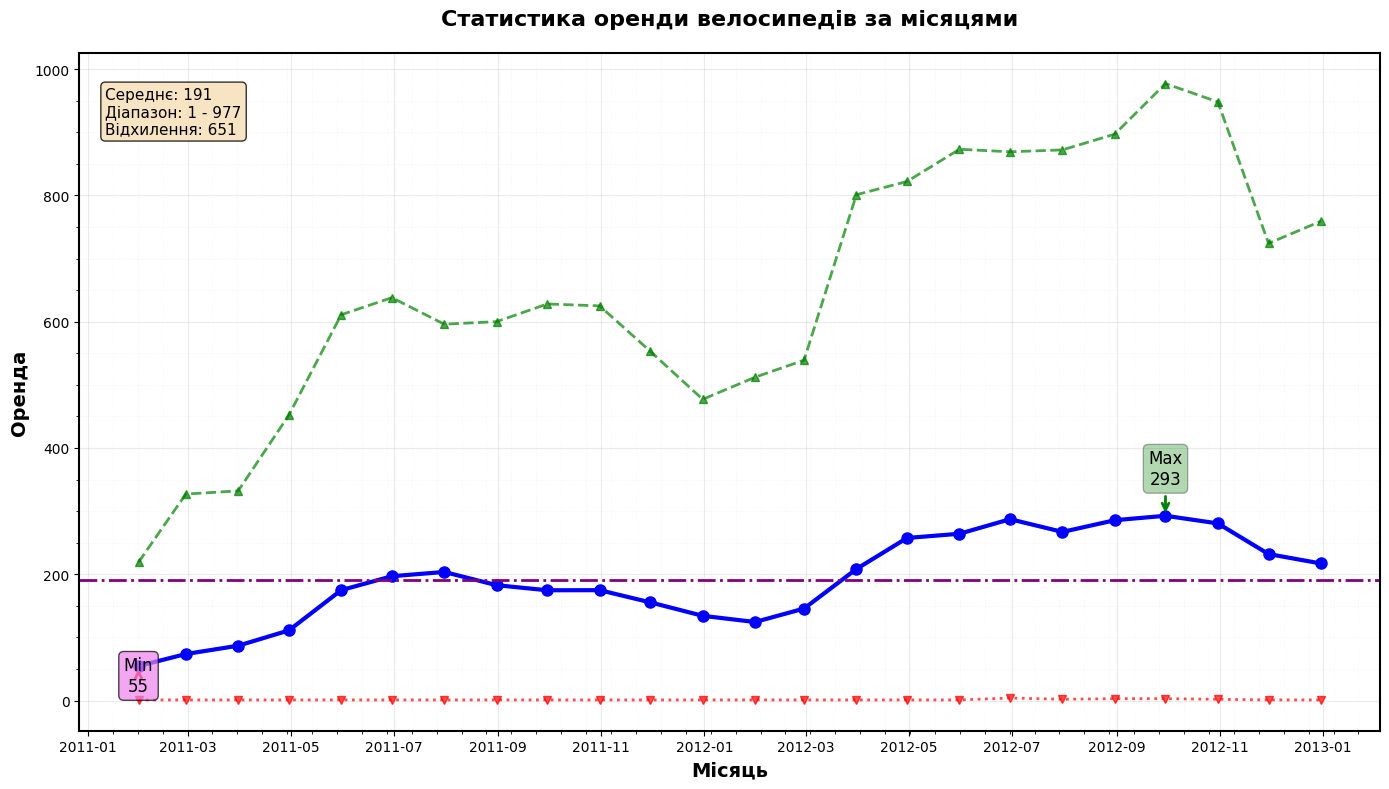

In [17]:
monthly_stats = df['count'].resample('M').agg(['mean', 'max', 'min'])

fig, ax = plt.subplots(figsize=(14, 8))


ax.plot(monthly_stats.index, monthly_stats['mean'], 'b-o', linewidth=3,
        label='Mean', markersize=8)
ax.plot(monthly_stats.index, monthly_stats['max'], 'g--^', linewidth=2,
        label='Max', markersize=6, alpha=0.7)
ax.plot(monthly_stats.index, monthly_stats['min'], 'r:v', linewidth=2,
        label='Min', markersize=6, alpha=0.7)


max_idx = monthly_stats['mean'].idxmax()
max_val = monthly_stats['mean'].max()
ax.annotate(f'Max\n{max_val:.0f}',
            xy=(max_idx, max_val), xytext=(max_idx, max_val + 50),
            arrowprops=dict(arrowstyle='->', color='green', lw=2),
            fontsize=12, ha='center',
            bbox=dict(boxstyle="round,pad=0.3", facecolor='green', alpha=0.3))

min_idx = monthly_stats['mean'].idxmin()
min_val = monthly_stats['mean'].min()
ax.annotate(f'Min\n{min_val:.0f}',
            xy=(min_idx, min_val), xytext=(min_idx, min_val - 40),
            arrowprops=dict(arrowstyle='->', color='red', lw=2),
            fontsize=12, ha='center',
            bbox=dict(boxstyle='round,pad=0.3', facecolor='violet', alpha=0.7))


ax.set_xlabel('Місяць', fontsize=14, fontweight='bold')
ax.set_ylabel('Оренда', fontsize=14, fontweight='bold')
ax.set_title('Статистика оренди велосипедів за місяцями',
             fontsize=16, fontweight='bold', pad=20)


ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
ax.xaxis.set_minor_locator(mdates.MonthLocator(interval=1))


ax.yaxis.set_minor_locator(plt.MultipleLocator(50))


overall_mean = monthly_stats['mean'].mean()
ax.axhline(y=overall_mean, color='purple', linestyle='-.', linewidth=2,
           label=f'Середнє за рік: {overall_mean:.0f}')


ax.minorticks_on()
ax.grid(True, which='major', linestyle='-', linewidth=0.8, alpha=0.25)
ax.grid(True, which='minor', linestyle=':', linewidth=0.6, alpha=0.15)


avg_mean = monthly_stats['mean'].mean()
global_min = monthly_stats['min'].min()
global_max = monthly_stats['max'].max()
avg_spread = (monthly_stats['max'] - monthly_stats['min']).mean()
textstr = (
    f"Середнє: {avg_mean:.0f}\n"
    f"Діапазон: {global_min:.0f} - {global_max:.0f}\n"
    f"Відхилення: {avg_spread:.0f}"
)
props = dict(boxstyle='round', facecolor='wheat', alpha=0.8)
ax.text(0.02, 0.95, textstr, transform=ax.transAxes, fontsize=11,
        verticalalignment='top', bbox=props)


for spine in ax.spines.values():
    spine.set_linewidth(1.5)

plt.tight_layout()
plt.show()